> **Results-only copy.** This is the executed notebook from the private FaultSage repository with one change: the training cell (section 3), which prints the learned model, is removed. Every other cell and every output is exactly as it was saved after the run on 25 November 2026. The code imports private modules, so it is a record of the run rather than something to execute here.

# Ranker: model choice and held-out result

* **Data**: real bugs from BugsInPy, split once by project (`src/faultsage/bench/splits/bugsinpy_v1.json`). Model choice and training use the **dev** projects only. The **test** projects appear once, at the end, read from the run record made after the model was frozen.
* **Task**: rank candidate files for each failing test; a hit means the file the developer fixed is ranked first (Top-1) or in the top k.
* **Shipped model**: the average of a logistic regression and a random forest, trained by `faultsage bench train` (`faultsage_engine/training.py`). This notebook calls the same code.

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from faultsage.bench.records import get_run

from faultsage_engine import WEIGHTS_FILE
from faultsage_engine.training import fit_weights

REPO = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "engine" / "tools"))
from compare_models import MODELS, baseline_hit, per_project  # noqa: E402

DEV_RUN = "2026-11-24_bugsinpy_dev_165944_reanalysed"
TEST_RUNS = {
    "first model": "2026-11-23_bugsinpy_test_090824",
    "current model": "2026-11-24_bugsinpy_test_170310_reanalysed",
}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Dev data: five projects

In [2]:
run = get_run(DEV_RUN)
cases = [c for c in run["cases"] if c.get("reproduced") and c.get("candidates")]
print(
    f"{len(cases)} dev bugs with candidates, {sum(len(c['candidates']) for c in cases)} candidates"
)
for p, n in Counter(c["project"] for c in cases).most_common():
    print(f"  {p:8s} {n}")

66 dev bugs with candidates, 986 candidates
  luigi    32
  black    22
  tqdm     8
  httpie   4


luigi's bugs only became usable after the benchmark harness learned to build old packages that need a C compiler and to skip pins deleted from PyPI. They matter: unlike black, luigi's bugs often sit at the crash line rather than in the most recent change.

## 2. Choose the model (dev only, leave one project out)

Train on every dev project but one, score Top-1 on the held-out project, repeat. Two summaries: the mean over bugs, and the mean over projects (so one big project cannot dominate).

In [3]:
rows = {}
for name, make in MODELS.items():
    pp = per_project(cases, make)
    n = Counter(c["project"] for c in cases)
    per_bug = sum(pp[p] * n[p] for p in pp) / sum(n.values())
    rows[name] = (per_bug, float(np.mean(list(pp.values()))), pp)
print(f"{'model':32s} per-bug  per-project  " + "  ".join(f"{p:6s}" for p in sorted(n)))
for name, (b, pr, pp) in rows.items():
    print(
        f"{name:32s} {b:.2f}     {pr:.2f}         "
        + "  ".join(f"{pp[p]:.2f}  " for p in sorted(pp))
    )
for name, key in (("top stack frame", "top_frame"), ("recently changed", "recent")):
    print(
        f"{name:32s} {np.mean([baseline_hit(c, key) for c in cases]):.2f}   (baseline, no training)"
    )

model                            per-bug  per-project  black   httpie  luigi   tqdm  
logistic regression              0.55     0.58         0.91    0.50    0.28    0.62  
gradient boosting, 200 trees     0.62     0.55         0.91    0.50    0.53    0.25  
histogram gradient boosting      0.59     0.53         0.91    0.50    0.47    0.25  
random forest, 500 trees         0.67     0.57         0.91    0.50    0.62    0.25  
average of logistic and forest   0.70     0.63         0.91    0.50    0.62    0.50  
top stack frame                  0.29   (baseline, no training)
recently changed                 0.45   (baseline, no training)


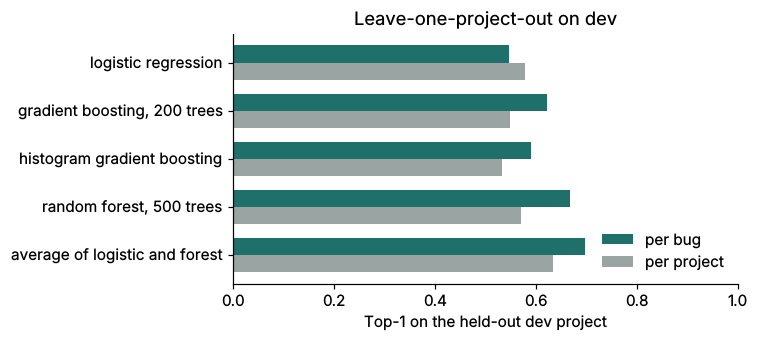

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
names = list(rows)
y = np.arange(len(names))
ax.barh(y - 0.18, [rows[k][0] for k in names], 0.36, label="per bug", color="#1f6f6a")
ax.barh(y + 0.18, [rows[k][1] for k in names], 0.36, label="per project", color="#9aa5a3")
ax.set_yticks(y, names)
ax.set_xlim(0, 1)
ax.set_xlabel("Top-1 on the held-out dev project")
ax.set_title("Leave-one-project-out on dev")
ax.invert_yaxis()
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()

The average of the logistic regression and the forest is best on both summaries: the forest is strong on luigi, the logistic regression on tqdm, and averaging keeps most of both.

## 3. Held-out test result (read only, never used for choosing or training)

In [6]:
labels = {
    "faultsage": "FaultSage",
    "top_frame": "Top stack frame",
    "recent": "Recently changed",
    "random": "Random",
}
results = {}
for tag, rid in TEST_RUNS.items():
    d = json.loads((REPO / "results" / "runs" / rid / "run.json").read_text())
    results[tag] = {"faultsage": d["metrics"]["faultsage"], **d["baselines"]}
    print(f"{tag}: run {rid}, {d['cases_reproduced']} bugs, weights {d['weights_version']}")
print(f"\n{'method':28s} Top-1  Top-3  Top-5")
for tag in TEST_RUNS:
    m = results[tag]["faultsage"]
    print(
        f"{'FaultSage, ' + tag:28s} {m['top1']['mean']:.2f}   {m['top3']['mean']:.2f}   {m['top5']['mean']:.2f}"
    )
for k in ("top_frame", "recent", "random"):
    m = results["current model"][k]
    print(
        f"{labels[k]:28s} {m['top1']['mean']:.2f}   {m['top3']['mean']:.2f}   {m['top5']['mean']:.2f}"
    )

first model: run 2026-11-23_bugsinpy_test_090824, 19 bugs, weights 2026-11-23_bugsinpy_dev_090631_reanalysed
current model: run 2026-11-24_bugsinpy_test_170310_reanalysed, 19 bugs, weights 2026-11-24_bugsinpy_dev_165944_reanalysed

method                       Top-1  Top-3  Top-5
FaultSage, first model       0.11   0.37   0.58
FaultSage, current model     0.47   0.79   0.84
Top stack frame              0.53   0.58   0.58
Recently changed             0.11   0.16   0.16
Random                       0.07   0.21   0.32


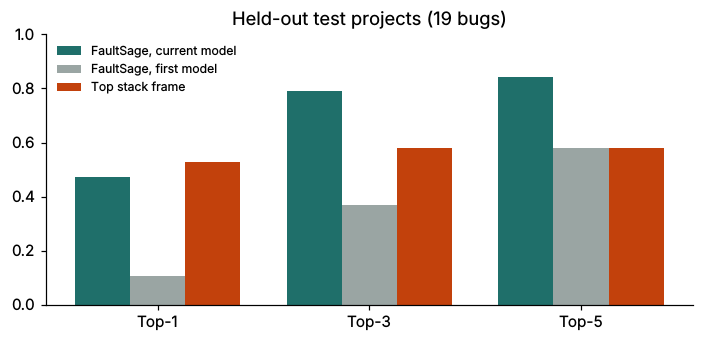

In [7]:
ks = ["top1", "top3", "top5"]
x = np.arange(3)
series = [
    ("FaultSage, current model", results["current model"]["faultsage"], "#1f6f6a"),
    ("FaultSage, first model", results["first model"]["faultsage"], "#9aa5a3"),
    ("Top stack frame", results["current model"]["top_frame"], "#c2410c"),
]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for i, (name, m, col) in enumerate(series):
    ax.bar(x + (i - 1) * 0.26, [m[k]["mean"] for k in ks], 0.26, label=name, color=col)
ax.set_xticks(x, ["Top-1", "Top-3", "Top-5"])
ax.set_ylim(0, 1)
ax.set_title("Held-out test projects (19 bugs)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

## 4. Conclusion

* On projects it never saw, the right file is in the top five for 84% of bugs (16 of 19), against 58% for the crash line. The first guess is about as good as the crash line (0.47 vs 0.53).
* The gain came from more varied training projects and a model chosen on dev, not from tuning on the test split.
* 19 test bugs, mostly from one project, give wide intervals; more test projects are the next step.